# E3 Unsupervised learning on the matched 2000 clip pilot

Do frozen Whisper features form groups that agree with accent labels? This is a separate pilot copy of `E3_01_unsupervised_learning_beginner.ipynb`. The existing 40,000-clip notebook and its results are unchanged.

Use the pilot's fixed 2,000-clip cache and 1,280/320/400 speaker split. **Fit and plot only the 1,600 training plus validation clips. Exclude all 400 test clips.** PCA and K-means receive embeddings only. UMAP provides a display, not the clustering input. Reveal accent and source labels after fitting. ARI and silhouette are exploratory measures, not test accuracy.

This analysis was added after the supervised pilot was inspected. It does not make the pilot test untouched again or drive the original full-study choices. Source and class are linked: all Singapore clips are MNSC and all non-Singapore clips are Common Voice.

## 1 Environment and fixed settings

Run all cells with **Singlish final fusion Python 3.14**. No packages are installed or upgraded. Settings follow the existing E3 method: standardized features, 50 PCA components and two K-means clusters with ten starts and seed 42. We do not choose settings using accent agreement. Two further seeds check initialization sensitivity. A separate analysis gives each development speaker equal weight.

In [1]:
from pathlib import Path
from collections import Counter
import datetime, hashlib, importlib.metadata, inspect, json, platform, sys, time
import joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import umap
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
%matplotlib inline

PROJECT_ROOT = Path('/home/mh/nusproj/singlish-whisper')
INPUT_DIR = PROJECT_ROOT / 'outputs/matched_2000_seed42'
OUTPUT_DIR = INPUT_DIR / 'e3_unsupervised'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
import experiment_common as common
SETTINGS = {'analysis_partitions': ['train', 'validation'], 'pca_components': 50,
            'pca_solver': 'full', 'clusters': 2, 'kmeans_n_init': 10, 'seed': 42,
            'stability_seeds': [7, 19], 'umap_neighbors': 15, 'umap_min_dist': 0.1,
            'umap_init': 'random', 'speaker_mean_check': True}
packages = {n: importlib.metadata.version(n) for n in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'umap-learn', 'matplotlib', 'nbformat', 'nbclient']}
started_utc = datetime.datetime.now(datetime.timezone.utc).isoformat()
run_started = time.perf_counter()
def sha256_file(path):
    with Path(path).open('rb') as f:
        return hashlib.file_digest(f, 'sha256').hexdigest()
print('Pilot input:', INPUT_DIR)
print('E3 output:', OUTPUT_DIR)
print('Python:', platform.python_version())
print('Packages:', json.dumps(packages, indent=2))
print('Fixed settings:', json.dumps(SETTINGS, indent=2))

/home/mh/miniconda3/envs/singlish-py314/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pilot input: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42
E3 output: /home/mh/nusproj/singlish-whisper/outputs/matched_2000_seed42/e3_unsupervised
Python: 3.14.7
Packages: {
  "numpy": "2.5.3",
  "pandas": "2.3.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "umap-learn": "0.5.12",
  "matplotlib": "3.11.2",
  "nbformat": "5.11.1",
  "nbclient": "0.11.0"
}
Fixed settings: {
  "analysis_partitions": [
    "train",
    "validation"
  ],
  "pca_components": 50,
  "pca_solver": "full",
  "clusters": 2,
  "kmeans_n_init": 10,
  "seed": 42,
  "stability_seeds": [
    7,
    19
  ],
  "umap_neighbors": 15,
  "umap_min_dist": 0.1,
  "umap_init": "random",
  "speaker_mean_check": true
}


## 2 Audit the pilot identities and exclude test speakers

Check the saved manifest against all 2,000 audio hashes and the exact saved split IDs. The Whisper cache has the original manifest fingerprint in its key; verify its audio preparation key, encoder revision, dimensions and finite values. Record file hashes. Do not rebuild audio, features or speaker partitions. Remove test embeddings before any analysis. Labels in the manifest are checked only for identity at this stage.

In [2]:
manifest_path = INPUT_DIR / 'dataset_manifest.csv'
split_path = INPUT_DIR / 'speaker_split.npz'
cache_path = INPUT_DIR / 'whisper_embeddings.npz'
frame = pd.read_csv(manifest_path, dtype={'clip_id': str, 'group': str, 'sha256': str})
assert len(frame) == 2000 and frame.clip_id.is_unique
assert frame.label.value_counts().to_dict() == {0: 1000, 1: 1000}
assert frame.group.nunique() == 883
assert not frame.sha256.duplicated().any()
fingerprint = hashlib.sha256(frame[['clip_id', 'label', 'group', 'sha256']].to_csv(index=False).encode()).hexdigest()
e2_report = json.loads((INPUT_DIR / 'e2_whisper/report.json').read_text())
assert fingerprint == e2_report['dataset_fingerprint']
assert all(sha256_file(p) == h for p, h in zip(frame.path, frame.sha256))
with np.load(split_path, allow_pickle=False) as saved:
    assert str(saved['fingerprint']) == fingerprint and int(saved['seed']) == 42
    assert np.array_equal(saved['clip_ids'], frame.clip_id.to_numpy(dtype=str))
    split = {name: saved[name].copy() for name in ['train', 'validation', 'test']}
assert [len(split[k]) for k in ['train', 'validation', 'test']] == [1280, 320, 400]
assert np.array_equal(np.sort(np.concatenate(list(split.values()))), np.arange(2000))
partition = np.full(len(frame), '', dtype=object)
for name, idx in split.items():
    partition[idx] = name
    assert frame.iloc[idx].label.value_counts().nunique() == 1
frame['partition'] = partition
assert frame.groupby('group').partition.nunique().max() == 1
saved_split_manifest = pd.read_csv(INPUT_DIR / 'split_manifest.csv')
assert saved_split_manifest.equals(frame)
feature_hash = hashlib.sha256((inspect.getsource(common.prepare_audio) + inspect.getsource(common.acoustic_features)).encode()).hexdigest()
expected_key = f'{fingerprint}|{feature_hash}|sr=16000|seconds=6|openai/whisper-base.en|real_audio_steps_v2|float32'
with np.load(cache_path, allow_pickle=False) as cache:
    assert str(cache['key']) == expected_key
    assert str(cache['model_name']) == 'openai/whisper-base.en'
    encoder_revision = str(cache['model_commit'])
    assert encoder_revision == '911407f4214e0e1d82085af863093ec0b66f9cd6'
    full_embeddings = cache['embeddings'].copy()
assert full_embeddings.shape == (2000, 512) and np.isfinite(full_embeddings).all()
dev_idx = np.sort(np.r_[split['train'], split['validation']])
development = frame.iloc[dev_idx].reset_index(drop=True)
excluded_test = frame.iloc[split['test']].copy()
X = full_embeddings[dev_idx].copy()
del full_embeddings
assert X.shape == (1600, 512) and development.group.nunique() == 707
assert set(development.clip_id).isdisjoint(excluded_test.clip_id)
assert set(development.group).isdisjoint(excluded_test.group)
input_audit = {'status': 'passed', 'dataset_fingerprint': fingerprint,
    'manifest_sha256': sha256_file(manifest_path), 'split_sha256': sha256_file(split_path),
    'split_manifest_sha256': sha256_file(INPUT_DIR / 'split_manifest.csv'),
    'embedding_cache_sha256': sha256_file(cache_path), 'embedding_cache_key': expected_key,
    'encoder': 'openai/whisper-base.en', 'encoder_revision': encoder_revision,
    'audio_hashes_matched': 2000, 'fit_clips': 1600, 'fit_speakers': 707,
    'excluded_test_clips': 400, 'excluded_test_speakers': 176,
    'fit_test_clip_overlap': 0, 'fit_test_speaker_overlap': 0,
    'fit_clip_ids_sha256': hashlib.sha256('\n'.join(development.clip_id).encode()).hexdigest(),
    'audio_reprepared': False, 'encoder_rerun': False}
display(development.groupby('partition').agg(clips=('clip_id', 'size'), speakers=('group', 'nunique')))
print('Audit passed; all 400 test clips and 176 test speakers excluded.')

,clips,speakers
partition,,
train,1280,566
validation,320,141


Audit passed; all 400 test clips and 176 test speakers excluded.


## 3 Fit scaling PCA and K-means without labels

The fitting function accepts only an embedding matrix. Each clip has equal weight. K-means uses all 50 PCA components, rather than the two shown in a plot. Two clusters implement the proposal's two-group question; they do not establish a natural number of accents. Silhouette uses all 1,600 development clips. The seed checks do not use accent labels to choose a winner.

In [3]:
def fit_unsupervised(matrix):
    scaler = StandardScaler()
    scaled = scaler.fit_transform(matrix)
    pca = PCA(n_components=SETTINGS['pca_components'], svd_solver=SETTINGS['pca_solver'])
    reduced = pca.fit_transform(scaled)
    kmeans = KMeans(n_clusters=SETTINGS['clusters'], n_init=SETTINGS['kmeans_n_init'], random_state=SETTINGS['seed'])
    clusters = kmeans.fit_predict(reduced)
    assert int(scaler.n_samples_seen_) == len(matrix) and pca.n_samples_ == len(matrix)
    return scaler, pca, reduced, kmeans, clusters

scaler, pca, reduced, kmeans, clusters = fit_unsupervised(X)
assert len(np.unique(clusters)) == 2
silhouette = float(silhouette_score(reduced, clusters))
stability = []
for seed in SETTINGS['stability_seeds']:
    alt = KMeans(n_clusters=2, n_init=10, random_state=seed).fit_predict(reduced)
    stability.append({'seed': seed, 'ari_to_seed42': float(adjusted_rand_score(clusters, alt))})
print('PCA variance retained:', f'{pca.explained_variance_ratio_.sum():.2%}')
print('Cluster sizes:', dict(sorted(Counter(int(k) for k in clusters).items())))
print('Silhouette:', f'{silhouette:.4f}')
display(pd.DataFrame(stability))

PCA variance retained: 57.21%
Cluster sizes: {0: 821, 1: 779}
Silhouette: 0.0707


,seed,ari_to_seed42
0,7,1.0
1,19,1.0


## 4 Make label-free UMAP and repeat with one point per speaker

Fit UMAP on the development PCA values with a fixed seed and no labels. It is only a display: it does not determine K-means clusters. Fit a separate scaler, PCA50 and K-means pipeline on each speaker's mean **raw** embedding to give all 707 development speakers equal weight. This is a sensitivity check, not an independent validation population.

In [4]:
umap_model = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                       random_state=42, init='random', n_jobs=1)
umap_xy = umap_model.fit_transform(reduced)
assert umap_xy.shape == (1600, 2) and np.isfinite(umap_xy).all()
speaker_groups = sorted(development.group.unique())
group_values = development.group.to_numpy()
speaker_X = np.stack([X[group_values == group].mean(axis=0) for group in speaker_groups])
speaker_scaler, speaker_pca, speaker_reduced, speaker_kmeans, speaker_clusters = fit_unsupervised(speaker_X)
speaker_silhouette = float(silhouette_score(speaker_reduced, speaker_clusters))
print('UMAP display:', umap_xy.shape)
print('Speaker mean fit:', speaker_X.shape, '; no test speakers')

UMAP display: (1600, 2)
Speaker mean fit: (707, 512) ; no test speakers


## 5 Reveal labels and draw the same maps with different colors

Compute adjusted Rand index (ARI) only after both clustering fits. ARI near zero indicates chance-level agreement; ARI one indicates identical partitions. Cluster IDs are arbitrary. Because class and corpus are perfectly linked, the label comparison is also a source comparison and cannot distinguish accent from recording or prompt effects. UMAP islands are not proof of accent groups.

,Non-Singapore,Singapore,Total,Singapore share
cluster,,,,
0,739,82,821,0.099878
1,61,718,779,0.921694


,analysis,observations,ARI with accent,silhouette
0,Clip weighted,1600,0.674248,0.070744
1,One mean per speaker,707,0.715342,0.079834


Speakers with recordings in both clusters: 54


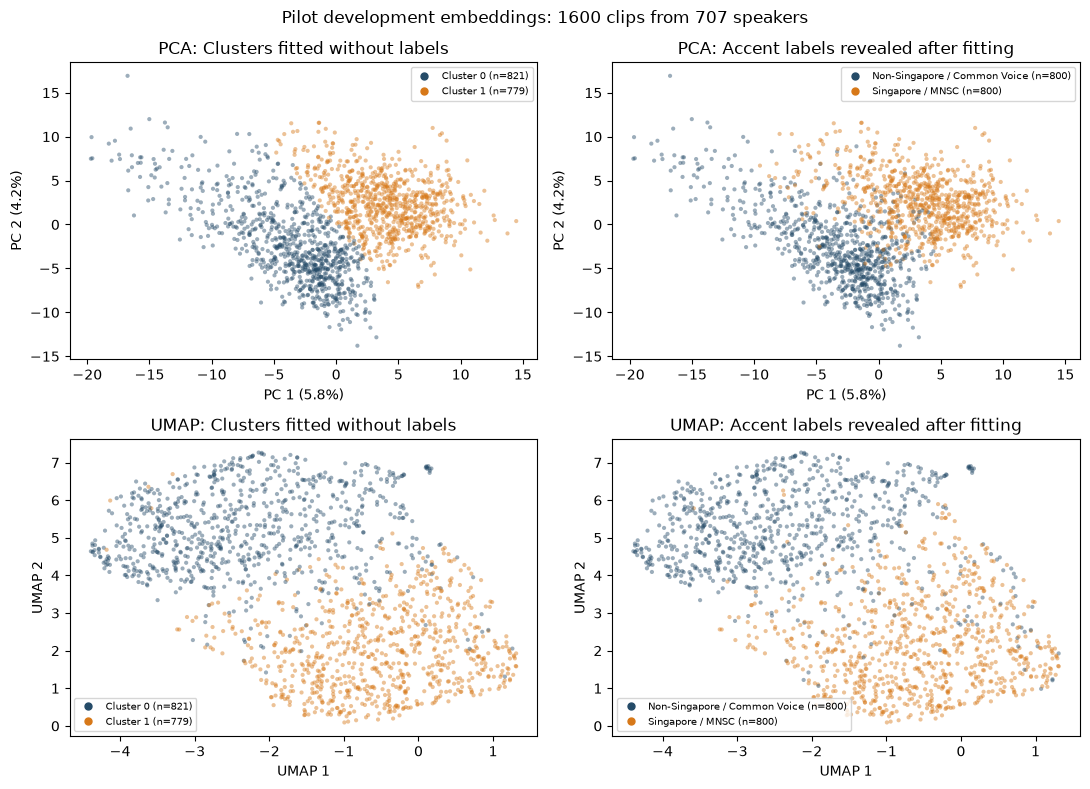

In [5]:
labels = development.label.to_numpy()
ari = float(adjusted_rand_score(labels, clusters))
assignments = development[['clip_id', 'group', 'partition', 'label']].copy()
assignments['source'] = np.where(labels == 1, 'MNSC', 'Common Voice')
assignments['cluster'] = clusters
assignments['pca_1'], assignments['pca_2'] = reduced[:, 0], reduced[:, 1]
assignments['umap_1'], assignments['umap_2'] = umap_xy[:, 0], umap_xy[:, 1]
speaker_labels = np.array([labels[group_values == group][0] for group in speaker_groups])
assert all(len(set(labels[group_values == group])) == 1 for group in speaker_groups)
speaker_ari = float(adjusted_rand_score(speaker_labels, speaker_clusters))
cluster_table = pd.crosstab(assignments.cluster, assignments.label).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
cluster_table.columns = ['Non-Singapore', 'Singapore']
cluster_table['Total'] = cluster_table.sum(axis=1)
cluster_table['Singapore share'] = cluster_table['Singapore'] / cluster_table['Total']
speaker_table = pd.crosstab(speaker_clusters, speaker_labels).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
split_cluster_speakers = int((assignments.groupby('group').cluster.nunique() > 1).sum())
display(cluster_table)
display(pd.DataFrame([
    {'analysis': 'Clip weighted', 'observations': len(X), 'ARI with accent': ari, 'silhouette': silhouette},
    {'analysis': 'One mean per speaker', 'observations': len(speaker_X), 'ARI with accent': speaker_ari, 'silhouette': speaker_silhouette},
]))
print('Speakers with recordings in both clusters:', split_cluster_speakers)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
draw_order = np.random.default_rng(42).permutation(len(X))
colors = ['#254B68', '#D77818']
for row, (xy, name, xlab, ylab) in enumerate([
    (reduced[:, :2], 'PCA', f'PC 1 ({pca.explained_variance_ratio_[0]:.1%})', f'PC 2 ({pca.explained_variance_ratio_[1]:.1%})'),
    (umap_xy, 'UMAP', 'UMAP 1', 'UMAP 2')]):
    for col, (categories, title, names) in enumerate([
        (clusters, 'Clusters fitted without labels', ['Cluster 0', 'Cluster 1']),
        (labels, 'Accent labels revealed after fitting', ['Non-Singapore / Common Voice', 'Singapore / MNSC'])]):
        ax = axes[row, col]
        ax.scatter(xy[draw_order, 0], xy[draw_order, 1], c=categories[draw_order],
                   cmap=ListedColormap(colors), vmin=-0.5, vmax=1.5, s=9, alpha=0.45, linewidths=0, rasterized=True)
        handles = [Line2D([], [], marker='o', linestyle='', color=colors[k], markersize=5,
                         label=f'{names[k]} (n={int((categories == k).sum())})') for k in [0, 1]]
        ax.legend(handles=handles, fontsize=7, loc='best')
        ax.set(title=f'{name}: {title}', xlabel=xlab, ylabel=ylab)
fig.suptitle('Pilot development embeddings: 1600 clips from 707 speakers')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'clustering.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 6 Save compact results and verify them

Keep per-clip assignments, settings, input hashes, environment, cluster composition and sensitivity metrics. Source-only fitted objects support independent replay. The report snapshot needs only this executed notebook, the JSON report, assignments CSV and verification JSON; its figures are already inline. The ten supervised test systems and their 400-clip comparison are unchanged.

In [6]:
assignments_path = OUTPUT_DIR / 'assignments.csv'
assignments.to_csv(assignments_path, index=False)
report = {'experiment': 'E3 matched 2000-clip pilot unsupervised learning',
    'scope': 'Development-only exploration; not held-out classification',
    'started_utc': started_utc, 'settings': SETTINGS, 'input_audit': input_audit,
    'python': platform.python_version(), 'packages': packages,
    'copied_from': 'notebooks/E3_01_unsupervised_learning_beginner.ipynb',
    'base_notebook_sha256': sha256_file(PROJECT_ROOT / 'notebooks/E3_01_unsupervised_learning_beginner.ipynb'),
    'clip_analysis': {'clips': 1600, 'speakers': 707, 'pca_variance_retained': float(pca.explained_variance_ratio_.sum()),
        'pca_first_two_variance': [float(v) for v in pca.explained_variance_ratio_[:2]],
        'silhouette': silhouette, 'adjusted_rand_index': ari,
        'cluster_composition': {str(k): {'non_singapore': int(cluster_table.loc[k, 'Non-Singapore']),
            'singapore': int(cluster_table.loc[k, 'Singapore']), 'total': int(cluster_table.loc[k, 'Total']),
            'singapore_share': float(cluster_table.loc[k, 'Singapore share'])} for k in [0, 1]},
        'speakers_with_clips_in_both_clusters': split_cluster_speakers, 'initialization_sensitivity': stability},
    'speaker_mean_analysis': {'speakers': len(speaker_X), 'adjusted_rand_index': speaker_ari,
        'silhouette': speaker_silhouette, 'pca_variance_retained': float(speaker_pca.explained_variance_ratio_.sum()),
        'cluster_composition': {str(k): {'non_singapore': int(speaker_table.loc[k, 0]),
                                        'singapore': int(speaker_table.loc[k, 1])} for k in [0, 1]}},
    'fit_labels_used': False, 'test_clips_analyzed': 0,
    'limitations': ['Class and recording source are confounded.',
        'Retrospective analysis after supervised pilot inspection; no independent-source validation.',
        'One fixed development population; two clusters and PCA50 fixed rather than selected.',
        'Speaker means are a weighting sensitivity check, not independent validation.',
        'UMAP is a visualization; ARI and silhouette are not test accuracy.'],
    'runtime_seconds': time.perf_counter() - run_started}
(OUTPUT_DIR / 'report.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
joblib.dump({'scaler': scaler, 'pca': pca, 'kmeans': kmeans, 'umap': umap_model,
             'speaker_scaler': speaker_scaler, 'speaker_pca': speaker_pca, 'speaker_kmeans': speaker_kmeans,
             'fit_clip_ids': development.clip_id.to_list(), 'speaker_groups': speaker_groups},
            OUTPUT_DIR / 'fitted_pipelines.joblib')
reloaded = pd.read_csv(assignments_path)
assert len(reloaded) == 1600 and reloaded.clip_id.is_unique
assert set(reloaded.partition) == {'train', 'validation'}
assert set(reloaded.group).isdisjoint(excluded_test.group)
assert np.array_equal(kmeans.predict(pca.transform(scaler.transform(X))), reloaded.cluster)
assert adjusted_rand_score(reloaded.label, reloaded.cluster) == ari
assert np.isclose(silhouette_score(reduced, reloaded.cluster), silhouette)
assert np.array_equal(speaker_kmeans.predict(speaker_pca.transform(speaker_scaler.transform(speaker_X))), speaker_clusters)
verification = {'status': 'passed', 'fit_clips': 1600, 'fit_speakers': 707,
    'excluded_test_clips': 400, 'fit_test_speaker_overlap': 0,
    'checks': ['All 2000 source audio hashes match the original pilot manifest.',
        'Original cache key, encoder revision, clip order and saved split verified.',
        'Scaling, PCA, K-means and UMAP use only development embeddings and no labels.',
        'Speaker means include development speakers only.',
        'Saved assignments replay exactly; ARI and silhouette recomputed.',
        'No supervised pilot artifact changed.'],
    'artifacts_sha256': {name: sha256_file(OUTPUT_DIR / name) for name in ['report.json', 'assignments.csv']}}
(OUTPUT_DIR / 'verification.json').write_text(json.dumps(verification, indent=2) + '\n')
display(Markdown(f'**Observed pilot result:** clip ARI **{ari:.4f}**, silhouette **{silhouette:.4f}**; '
                 f'speaker-mean ARI **{speaker_ari:.4f}**. '
                 'These describe development embeddings, not held-out accent accuracy.'))
print('Saved report, assignments, verification and source-only fitted pipelines.')

**Observed pilot result:** clip ARI **0.6742**, silhouette **0.0707**; speaker-mean ARI **0.7153**. These describe development embeddings, not held-out accent accuracy.

Saved report, assignments, verification and source-only fitted pipelines.


## Interpretation

Use the observed ARI, silhouette, cluster composition and speaker-mean check together. Clusters can reflect source, speaker, microphone, room and prompt as well as accent. An apparent grouping does not justify using cluster IDs as accent labels. No classifier or supervised setting is changed by this exploration. The 40,000-clip E3 study remains a separate experiment.